# Homework <a class="anchor" id="section_homework"></a>

**HW 2/1**: <br>
Smart up our plotter to be able to customize the hard-coded layout setup inside the function. Add more custom feature that you would like to use.

**HW 2/2**: <br>
Upgrade the BSM call option pricer to be able to return the greeks as well, not just the price.

**HW 2/3**: <br>
Implement the BSM pricer for European put option.

**HW 2/4**: <br>
With the call and put pricer, check if Put-Call parity holds in practice.

In [1]:
#HW 2/1
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Union, Optional

""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """

DEFAULT_LAYOUT = {
    'figsize': (8, 4),
    'linestyle': 'solid',
    'linewidth': 4,
    'colors': None,            # list of colors, one per line (None = matplotlib defaults)
    'title': None,
    'x_label': None,
    'y_label': None,
    'title_fontsize': 20,
    'label_fontsize': 16,
    'legend_fontsize': 16,
    'title_pad': 30,           # moving the title a little further away from the plot
    'label_pad': 20,           # moving the axis label a little further away from the plot
    'grid': False,
    'hline': 0,                # horizontal dashed line, None = do not draw
    'xlim': None,
    'ylim': None,
}


def my_plotter(x: List[float],
               y: Union[List[float], List[List[float]]],
               layout: Optional[Dict] = None,
               names: Optional[List[str]] = None) -> None:
    # merge defaults with user settings (user values win)
    cfg = {**DEFAULT_LAYOUT, **(layout or {})}

    # protect against typos in layout keys
    unknown = set(cfg) - set(DEFAULT_LAYOUT)
    if unknown:
        raise ValueError(f"Unknown layout keys: {unknown}")

    # a single line is wrapped into a list (works for int, float and numpy arrays)
    y_arr = np.asarray(y, dtype=float)
    y = [y_arr] if y_arr.ndim == 1 else list(y_arr)

    plt.figure(figsize=cfg['figsize'])
    lines = []
    show_legend = names is not None

    if show_legend and len(names) != len(y):
        raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' adds a counter to the loop """
    for i, y_item in enumerate(y):
        plot_kwargs = {
            'linestyle': cfg['linestyle'],
            'linewidth': cfg['linewidth'],
        }
        if show_legend:
            plot_kwargs['label'] = names[i]
        if cfg['colors'] is not None:
            plot_kwargs['color'] = cfg['colors'][i % len(cfg['colors'])]
        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=cfg['legend_fontsize'])
    if cfg['title']:
        plt.title(cfg['title'], fontsize=cfg['title_fontsize'], pad=cfg['title_pad'])
    if cfg['x_label']:
        plt.xlabel(cfg['x_label'], fontsize=cfg['label_fontsize'], labelpad=cfg['label_pad'])
    if cfg['y_label']:
        plt.ylabel(cfg['y_label'], fontsize=cfg['label_fontsize'], labelpad=cfg['label_pad'])

    """ enhance axes """
    ax = plt.gca()  # gca: get current axes
    if cfg['hline'] is not None:
        ax.axhline(cfg['hline'], linestyle='--', color='black', linewidth=1)
    if cfg['xlim']:
        ax.set_xlim(cfg['xlim'])
    if cfg['ylim']:
        ax.set_ylim(cfg['ylim'])
    if cfg['grid']:
        ax.grid(True, alpha=0.3)

    plt.show()

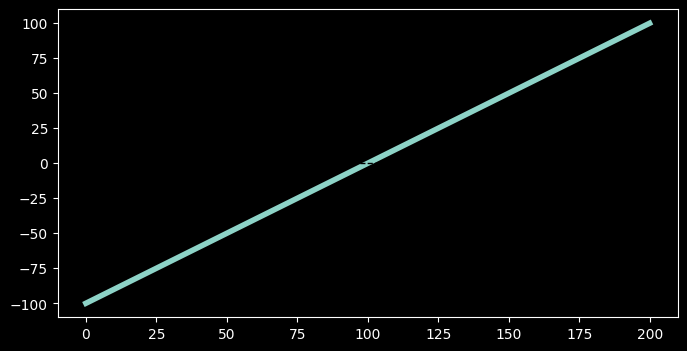

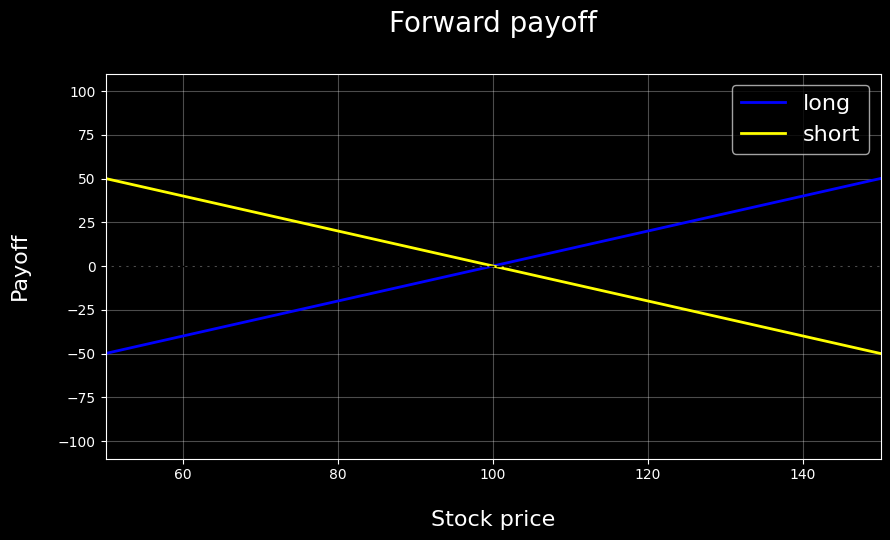

In [2]:
x = np.arange(0, 200, 0.1)
y_long = x - 100
y_short = -y_long

my_plotter(x, y_long)  # defaults

my_plotter(x, [y_long, y_short],
           layout={'title': 'Forward payoff', 'x_label': 'Stock price', 'y_label': 'Payoff',
                   'colors': ['blue', 'yellow'], 'linewidth': 2, 'grid': True,
                   'figsize': (10, 5), 'xlim': (50, 150)},
           names=['long', 'short'])

In [3]:
import numpy as np
from scipy.stats import norm
from typing import Dict, List, Union


def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float,
                           K: Union[float, List[float], np.ndarray],
                           greeks: bool = False) -> Union[np.ndarray, Dict[str, np.ndarray]]:
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    param greeks: if False, returns only the price (as before);
                  if True, returns a dict with the price and the greeks

    return: np.ndarray of prices, or dict with keys
            'price', 'delta', 'gamma', 'vega', 'theta', 'rho'
    """
    # check conditions
    assert sigma > 0
    assert T > 0

    K = np.atleast_1d(np.asarray(K, dtype=float))

    sqrt_T = np.sqrt(T)
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt_T)
    d2 = d1 - sigma * sqrt_T

    N_d1 = norm.cdf(d1)
    N_d2 = norm.cdf(d2)
    discounted_K = K * np.exp(-r * T)

    price = N_d1 * S0 - discounted_K * N_d2

    if not greeks:
        return price

    pdf_d1 = norm.pdf(d1)

    return {
        'price': price,
        'delta': N_d1,                                              # dC/dS0
        'gamma': pdf_d1 / (S0 * sigma * sqrt_T),                    # d2C/dS0^2
        'vega':  S0 * pdf_d1 * sqrt_T,                              # dC/dsigma
        'theta': -S0 * pdf_d1 * sigma / (2 * sqrt_T)
                 - r * discounted_K * N_d2,                         # dC/dt (t = calendar time)
        'rho':   K * T * np.exp(-r * T) * N_d2,                     # dC/dr
    }

In [4]:
res = black_scholes_eur_call(r=0.05, T=1.0, S0=100.0, sigma=0.3, K=100.0, greeks=True)
for name, value in res.items():
    print(f"{name:6s} {value[0]:.4f}")

price  14.2313
delta  0.6243
gamma  0.0126
vega   37.9433
theta  -8.1012
rho    48.1939


In [5]:
#HW 2/3

def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float,
                          K: Union[float, List[float], np.ndarray],
                          greeks: bool = False) -> Union[np.ndarray, Dict[str, np.ndarray]]:
    """
    Black-Scholes pricer of European put option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    param greeks: if False, returns only the price;
                  if True, returns a dict with the price and the greeks

    return: np.ndarray of prices, or dict with keys
            'price', 'delta', 'gamma', 'vega', 'theta', 'rho'
    """
    assert sigma > 0
    assert T > 0

    K = np.atleast_1d(np.asarray(K, dtype=float))

    sqrt_T = np.sqrt(T)
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt_T)
    d2 = d1 - sigma * sqrt_T

    N_minus_d1 = norm.cdf(-d1)
    N_minus_d2 = norm.cdf(-d2)
    discounted_K = K * np.exp(-r * T)

    price = discounted_K * N_minus_d2 - S0 * N_minus_d1

    if not greeks:
        return price

    pdf_d1 = norm.pdf(d1)

    return {
        'price': price,
        'delta': norm.cdf(d1) - 1.0,                                # dP/dS0 (between -1 and 0)
        'gamma': pdf_d1 / (S0 * sigma * sqrt_T),                    # same as for call
        'vega':  S0 * pdf_d1 * sqrt_T,                              # same as for call
        'theta': -S0 * pdf_d1 * sigma / (2 * sqrt_T)
                 + r * discounted_K * N_minus_d2,                   # dP/dt
        'rho':   -K * T * np.exp(-r * T) * N_minus_d2,              # dP/dr (negative)
    }

In [6]:
res = black_scholes_eur_put(r=0.05, T=1.0, S0=100.0, sigma=0.3, K=100.0, greeks=True)
for name, value in res.items():
    print(f"{name:6s} {value[0]:.4f}")

price  9.3542
delta  -0.3757
gamma  0.0126
vega   37.9433
theta  -3.3450
rho    -46.9290


In [7]:
# HW 2/4
import itertools
#single case
r, T, S0, sigma = 0.05, 1.0, 20.0, 0.3
K = np.arange(10.0, 30.0, 0.01)

C = black_scholes_eur_call(r, T, S0, sigma, K)
P = black_scholes_eur_put(r, T, S0, sigma, K)

lhs = C - P
rhs = S0 - K * np.exp(-r * T)

print("max abs diff:", np.max(np.abs(lhs - rhs)))

max abs diff: 5.329070518200751e-15


In [8]:
#multiple parameters case
r_list     = [0.0, 0.01, 0.05, 0.10]
T_list     = [0.1, 0.5, 1.0, 2.0, 5.0]
S0_list    = [10.0, 20.0, 100.0]
sigma_list = [0.1, 0.3, 0.8]
K = np.arange(5.0, 150.0, 0.5)

worst = 0.0
for r, T, S0, sigma in itertools.product(r_list, T_list, S0_list, sigma_list):
    C = black_scholes_eur_call(r, T, S0, sigma, K)
    P = black_scholes_eur_put(r, T, S0, sigma, K)
    err = np.max(np.abs((C - P) - (S0 - K * np.exp(-r * T))))
    worst = max(worst, err)

print("worst error over all combinations:", worst)
#the error is very small, parity indeed holds

worst error over all combinations: 2.842170943040401e-14
